# Estudos concluídos de pilates, fisioterapia, mobilidade e força

Cortes da camada gold no snapshot de 15/10/2026: 12.405 ensaios clínicos concluídos cuja intervenção testada é pilates, fisioterapia, mobilidade ou força. Um estudo pode entrar em mais de um grupo. As listas são abertas no DuckDB e a contagem é de estudo distinto.


In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data" / "clinical_trials.duckdb").exists():
    ROOT = ROOT.parent
DB_PATH = ROOT / "data" / "clinical_trials.duckdb"

con = duckdb.connect(str(DB_PATH), read_only=True)

ROTULOS_GRUPO = {
    "forca": "Força",
    "mobilidade": "Mobilidade",
    "fisioterapia": "Fisioterapia",
    "pilates": "Pilates",
}


def consultar(sql: str) -> pd.DataFrame:
    return con.execute(sql).fetchdf()


def barras(df: pd.DataFrame, titulo: str, xlabel: str) -> None:
    plot = df.iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, max(3.2, 0.38 * len(plot))))
    ax.barh(plot.iloc[:, 0].astype(str), plot.iloc[:, 1])
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(df.columns[0])
    fig.tight_layout()
    plt.show()


total = consultar("SELECT count(*) AS estudos FROM gold.estudos").iloc[0, 0]
print(f"{total} estudos na gold")


12405 estudos na gold


In [2]:
primeiras = consultar(
    """
    SELECT *
    FROM gold.estudos
    ORDER BY nct_id
    LIMIT 5
    """
)
ultimas = consultar(
    """
    SELECT *
    FROM gold.estudos
    ORDER BY nct_id DESC
    LIMIT 5
    """
)
display(primeiras)
display(ultimas.iloc[::-1].reset_index(drop=True))


,nct_id,brief_title,official_title,brief_summary,study_type,phase,phases,overall_status,start_date,completion_date,...,gender,conditions,interventions,mesh_terms,countries_current,lead_sponsors,were_results_reported,termos_encontrados,url,_gold_at
0,NCT00000399,Bone Estrogen Strength Training,Bone Estrogen Strength Training (BEST),"We started the Bone, Estrogen, Strength Traini...",INTERVENTIONAL,PHASE2,[PHASE2],COMPLETED,1995-08-31,2001-01-31,...,FEMALE,"[{'name': 'Osteoporosis', 'name_normalized': '...","[{'intervention_type': 'DRUG', 'name': 'Hormon...","[{'mesh_term': 'Bone Diseases, Metabolic', 'me...","[{'name': 'United States', 'removed': False}]","[{'agency_class': 'OTHER', 'lead_or_collaborat...",False,[forca],https://clinicaltrials.gov/study/NCT00000399,2026-10-15 07:51:48.152022-03:00
1,NCT00000409,Spine Patient Outcomes Research Trial (SPORT):...,Spine Patient Outcomes Research Trial (SPORT):...,This study tests the effectiveness of differen...,INTERVENTIONAL,PHASE4,[PHASE4],COMPLETED,2000-03-31,2015-04-30,...,ALL,"[{'name': 'Spondylolisthesis', 'name_normalize...","[{'intervention_type': 'PROCEDURE', 'name': 'D...","[{'mesh_term': 'Spondylolysis', 'mesh_type': '...","[{'name': 'United States', 'removed': False}]","[{'agency_class': 'OTHER', 'lead_or_collaborat...",False,[fisioterapia],https://clinicaltrials.gov/study/NCT00000409,2026-10-15 07:51:48.152022-03:00
2,NCT00000410,Spine Patient Outcomes Research Trial (SPORT) ...,Spine Patient Outcomes Research Trial (SPORT):...,This study tests the effectiveness of differen...,INTERVENTIONAL,PHASE4,[PHASE4],COMPLETED,2000-03-31,2015-04-30,...,ALL,"[{'name': 'Herniated Disc', 'name_normalized':...","[{'intervention_type': 'PROCEDURE', 'name': 'D...","[{'mesh_term': 'Spinal Diseases', 'mesh_type':...","[{'name': 'United States', 'removed': False}]","[{'agency_class': 'OTHER', 'lead_or_collaborat...",False,"[mobilidade, fisioterapia]",https://clinicaltrials.gov/study/NCT00000410,2026-10-15 07:51:48.152022-03:00
3,NCT00000411,Spine Patient Outcomes Research Trial (SPORT):...,Spine Patient Outcomes Research Trial (SPORT):...,This study tests the effectiveness of differen...,INTERVENTIONAL,PHASE4,[PHASE4],COMPLETED,2000-03-31,2015-04-30,...,ALL,"[{'name': 'Spinal Stenosis', 'name_normalized'...","[{'intervention_type': 'PROCEDURE', 'name': 'D...","[{'mesh_term': 'Spinal Diseases', 'mesh_type':...","[{'name': 'United States', 'removed': False}]","[{'agency_class': 'OTHER', 'lead_or_collaborat...",False,[fisioterapia],https://clinicaltrials.gov/study/NCT00000411,2026-10-15 07:51:48.152022-03:00
4,NCT00000434,Impact of Exercise on Older Persons With Osteo...,Impact of Exercise on Older Persons With Osteo...,Previous studies have found that exercise can ...,INTERVENTIONAL,PHASE2,[PHASE2],COMPLETED,1983-12-31,2003-09-30,...,ALL,"[{'name': 'Osteoarthritis', 'name_normalized':...","[{'intervention_type': 'BEHAVIORAL', 'name': '...","[{'mesh_term': 'Arthritis', 'mesh_type': 'mesh...","[{'name': 'United States', 'removed': False}]","[{'agency_class': 'NIH', 'lead_or_collaborator...",False,"[mobilidade, forca]",https://clinicaltrials.gov/study/NCT00000434,2026-10-15 07:51:48.152022-03:00


,nct_id,brief_title,official_title,brief_summary,study_type,phase,phases,overall_status,start_date,completion_date,...,gender,conditions,interventions,mesh_terms,countries_current,lead_sponsors,were_results_reported,termos_encontrados,url,_gold_at
0,NCT07870083,Effect of an 8-Week Core Exercise Program on J...,The Effect of an 8-Week Core Exercise Program ...,This randomized controlled trial examines the ...,INTERVENTIONAL,NA,[NA],COMPLETED,2026-05-02,2026-06-30,...,MALE,"[{'name': 'Athletic Performance', 'name_normal...","[{'intervention_type': 'BEHAVIORAL', 'name': '...",[],"[{'name': 'Turkey (Türkiye)', 'removed': False}]","[{'agency_class': 'OTHER', 'lead_or_collaborat...",False,[forca],https://clinicaltrials.gov/study/NCT07870083,2026-10-15 07:51:48.152022-03:00
1,NCT07871318,Nutraceutical Supplementation Combined With Ph...,Effects of Nutraceutical Supplementation Combi...,Rotator cuff tendinopathy is a common cause of...,INTERVENTIONAL,NA,[NA],COMPLETED,2024-10-03,2025-05-05,...,ALL,"[{'name': 'Rotator Cuff Tendinopathy', 'name_n...","[{'intervention_type': 'DIETARY_SUPPLEMENT', '...","[{'mesh_term': 'Arthralgia', 'mesh_type': 'mes...","[{'name': 'Italy', 'removed': False}]","[{'agency_class': 'OTHER', 'lead_or_collaborat...",False,"[mobilidade, forca, fisioterapia]",https://clinicaltrials.gov/study/NCT07871318,2026-10-15 07:51:48.152022-03:00
2,NCT07872280,"Neuromuscular Facilitation Protocol on Pain, R...",Effects of Neuromuscular Facilitation Protocol...,An individual can suffer from knee osteoarthri...,INTERVENTIONAL,NA,[NA],COMPLETED,2026-01-02,2026-04-20,...,ALL,"[{'name': 'Knee Osteoarthristis', 'name_normal...","[{'intervention_type': 'OTHER', 'name': 'Stand...","[{'mesh_term': 'Osteoarthritis', 'mesh_type': ...","[{'name': 'Pakistan', 'removed': False}]","[{'agency_class': 'OTHER', 'lead_or_collaborat...",False,"[forca, fisioterapia]",https://clinicaltrials.gov/study/NCT07872280,2026-10-15 07:51:48.152022-03:00
3,NCT07872345,Alternative Treatment in Fibromyalgia,Effectiveness of Pain Neuroscience Education a...,The goal of this randomized control trial is t...,INTERVENTIONAL,NA,[NA],COMPLETED,2025-09-01,2026-09-08,...,FEMALE,"[{'name': 'Fibromyalgia', 'name_normalized': '...","[{'intervention_type': 'OTHER', 'name': 'Neuro...","[{'mesh_term': 'Muscular Diseases', 'mesh_type...","[{'name': 'Spain', 'removed': False}]","[{'agency_class': 'OTHER', 'lead_or_collaborat...",False,"[mobilidade, forca]",https://clinicaltrials.gov/study/NCT07872345,2026-10-15 07:51:48.152022-03:00
4,NCT07872748,PNF and Shoulder Function in Adhesive Capsulitis,INVESTIGATION OF THE EFFECTS OF PROPRIOCEPTIVE...,This study aimed to investigate the effects of...,INTERVENTIONAL,NA,[NA],COMPLETED,2024-01-01,2025-12-01,...,ALL,[{'name': 'Proprioceptive Neuromuscular Facili...,"[{'intervention_type': 'OTHER', 'name': 'PNF E...","[{'mesh_term': 'Joint Diseases', 'mesh_type': ...","[{'name': 'Turkey (Türkiye)', 'removed': False}]","[{'agency_class': 'OTHER', 'lead_or_collaborat...",False,[fisioterapia],https://clinicaltrials.gov/study/NCT07872748,2026-10-15 07:51:48.152022-03:00


In [3]:
primeiras_referencias = consultar(
    """
    SELECT *
    FROM gold.referencias
    ORDER BY nct_id, pmid
    LIMIT 5
    """
)
ultimas_referencias = consultar(
    """
    SELECT *
    FROM gold.referencias
    ORDER BY nct_id DESC, pmid DESC
    LIMIT 5
    """
)
display(primeiras_referencias)
display(ultimas_referencias.iloc[::-1].reset_index(drop=True))


,nct_id,pmid,reference_type,citation,titulo,periodico,ano,resumo,busca_status
0,NCT00000399,14608080,BACKGROUND,"Harris MM, Houtkooper LB, Stanford VA, Parkhil...",Dietary iron is associated with bone mineral d...,The Journal of nutrition,2003,Healthy nonsmoking postmenopausal women (n = 2...,ok
1,NCT00000399,25785226,DERIVED,"Harris M, Farrell V, Houtkooper L, Going S, Lo...",Associations of polyunsaturated Fatty Acid int...,Journal of osteoporosis,2015,A secondary analysis of cross-sectional data w...,ok
2,NCT00000409,10787504,BACKGROUND,"Weinstein JN, Brown PW, Hanscom B, Walsh T, Ne...",Designing an ambulatory clinical practice for ...,Quality management in health care,2000,Development of a new program for diagnosis and...,ok
3,NCT00000409,12065987,BACKGROUND,"Birkmeyer NJ, Weinstein JN, Tosteson AN, Toste...",Design of the Spine Patient outcomes Research ...,Spine,2002,SUMMARY OF BACKGROUND DATA: The Spine Patient ...,ok
4,NCT00000409,12642770,BACKGROUND,"Walsh TL, Hanscom B, Lurie JD, Weinstein JN. I...",Is a condition-specific instrument for patient...,Spine,2003,STUDY DESIGN: Analysis of longitudinal data co...,ok


,nct_id,pmid,reference_type,citation,titulo,periodico,ano,resumo,busca_status
0,NCT07868094,25923435,BACKGROUND,"Tassonyi E, Pongracz A, Nemes R, Asztalos L, L...",Reversal of Pipecuronium-Induced Moderate Neur...,Anesthesia and analgesia,2015,BACKGROUND: Pipecuronium is a steroidal neurom...,ok
1,NCT07868094,26646837,BACKGROUND,"Takazawa T, Mitsuhata H, Mertes PM. Sugammadex...",Sugammadex and rocuronium-induced anaphylaxis.,Journal of anesthesia,2016,Perioperative anaphylaxis is a life-threatenin...,ok
2,NCT07868094,30169407,BACKGROUND,"Tassonyi E, Asztalos L, Szabo-Maak Z, Nemes R,...",Reversal of Deep Pipecuronium-Induced Neuromus...,Anesthesia and analgesia,2018,BACKGROUND: Certain surgical interventions may...,ok
3,NCT07868094,31032211,BACKGROUND,"Pauli H, Eladawy M, Park J. Anesthesia for rob...",Anesthesia for robotic thoracic surgery.,Annals of cardiothoracic surgery,2019,Robotically assisted thoracic surgery (RATS) t...,ok
4,NCT07868094,36377554,BACKGROUND,"Fuchs-Buder T, Romero CS, Lewald H, Lamperti M...",Peri-operative management of neuromuscular blo...,European journal of anaesthesiology,2023,Recent data indicated a high incidence of inap...,ok


## Grupos

Cada barra é um grupo encontrado na intervenção. A soma passa de 12.405 porque o mesmo ensaio pode cair, por exemplo, em mobilidade e força.


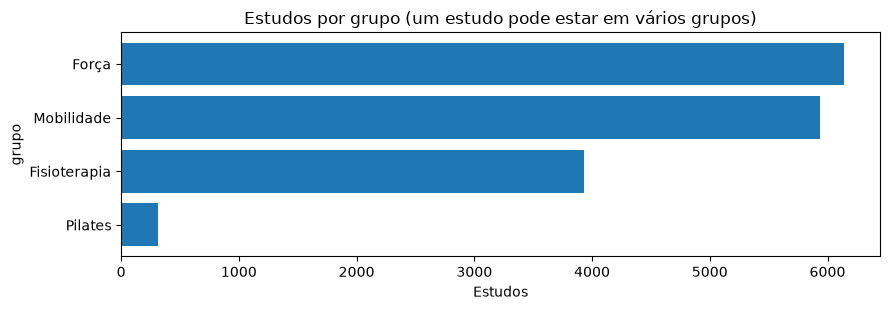

In [4]:
grupos = consultar(
    """
    SELECT unnest AS grupo, count(DISTINCT nct_id) AS estudos
    FROM gold.estudos, unnest(termos_encontrados)
    GROUP BY 1
    ORDER BY estudos DESC
    """
)
grupos["grupo"] = grupos["grupo"].map(ROTULOS_GRUPO).fillna(grupos["grupo"])
barras(
    grupos,
    "Estudos por grupo (um estudo pode estar em vários grupos)",
    "Estudos",
)


## Enfermidades

O termo MeSH é o vocabulário controlado. O nome livre é o que o registro declarou em condições. Os dois cortes não se substituem.


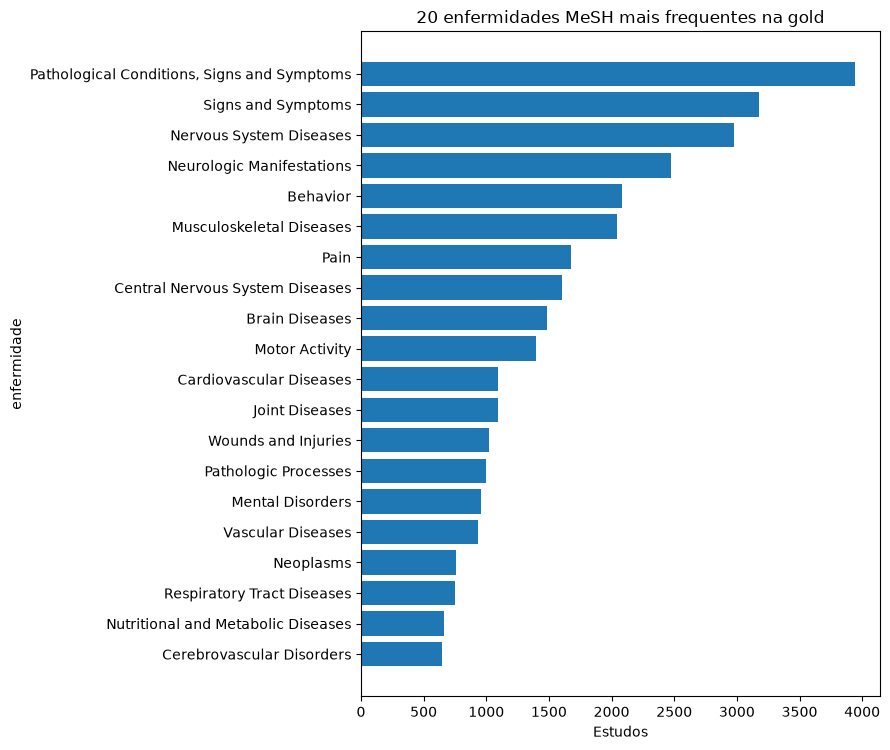

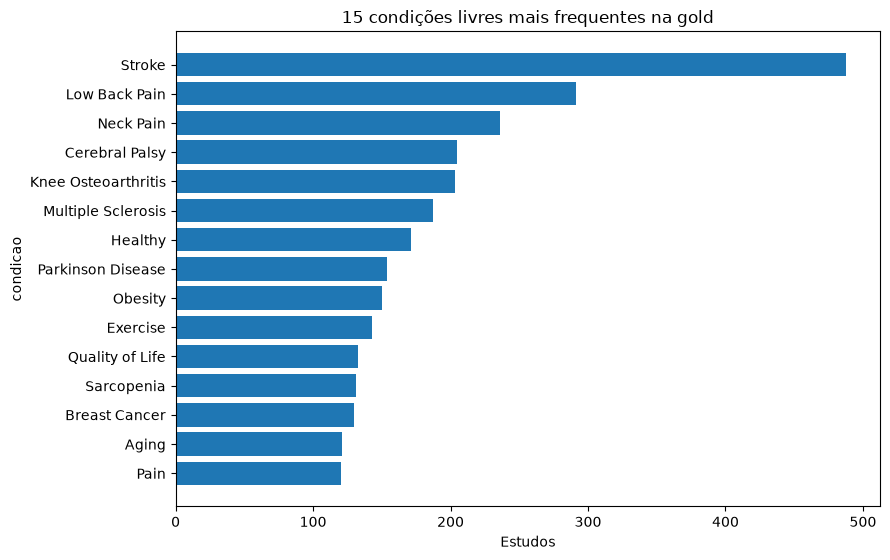

In [5]:
mesh = consultar(
    """
    SELECT unnest.mesh_term AS enfermidade, count(DISTINCT nct_id) AS estudos
    FROM gold.estudos, unnest(mesh_terms)
    WHERE unnest.mesh_term IS NOT NULL
    GROUP BY 1
    ORDER BY estudos DESC
    LIMIT 20
    """
)
barras(mesh, "20 enfermidades MeSH mais frequentes na gold", "Estudos")

condicoes = consultar(
    """
    SELECT unnest.name AS condicao, count(DISTINCT nct_id) AS estudos
    FROM gold.estudos, unnest(conditions)
    WHERE unnest.name IS NOT NULL
    GROUP BY 1
    ORDER BY estudos DESC
    LIMIT 15
    """
)
barras(condicoes, "15 condições livres mais frequentes na gold", "Estudos")


## Intervenções

O tipo separa exercício de fármaco, dispositivo ou procedimento quando o estudo tem mais de um braço. O nome é o rótulo declarado no ensaio.


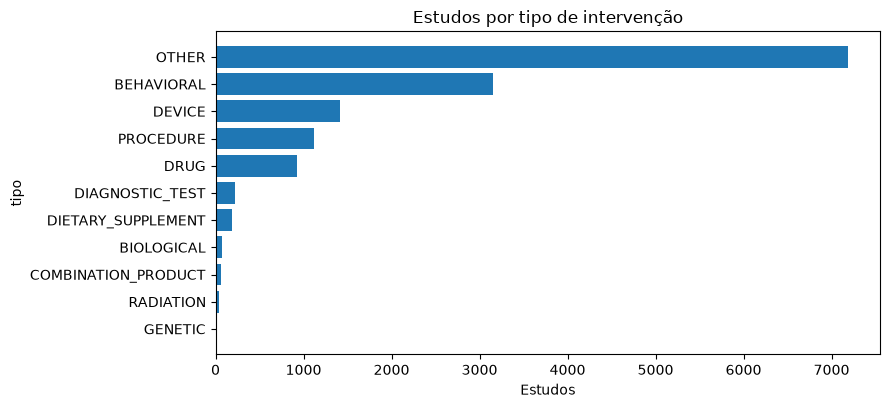

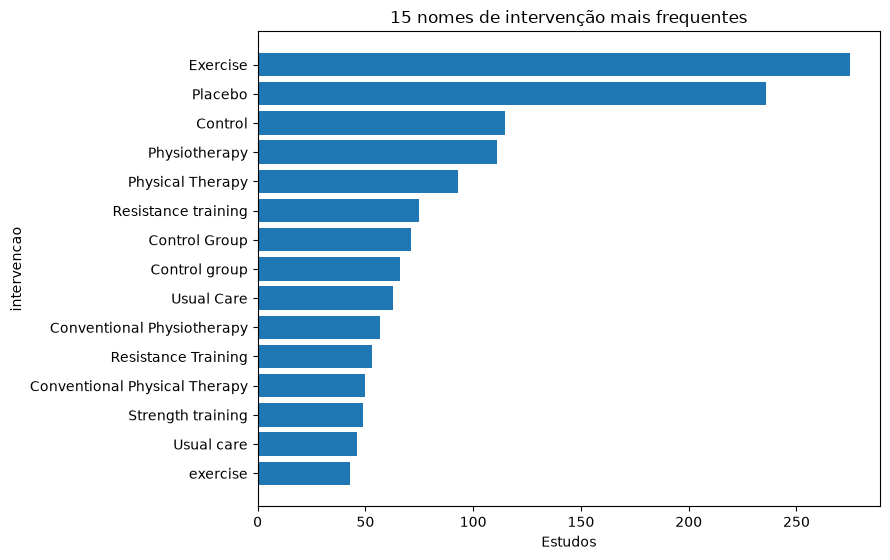

In [6]:
tipos = consultar(
    """
    SELECT unnest.intervention_type AS tipo, count(DISTINCT nct_id) AS estudos
    FROM gold.estudos, unnest(interventions)
    WHERE unnest.intervention_type IS NOT NULL
    GROUP BY 1
    ORDER BY estudos DESC
    """
)
barras(tipos, "Estudos por tipo de intervenção", "Estudos")

nomes = consultar(
    """
    SELECT unnest.name AS intervencao, count(DISTINCT nct_id) AS estudos
    FROM gold.estudos, unnest(interventions)
    WHERE unnest.name IS NOT NULL
    GROUP BY 1
    ORDER BY estudos DESC
    LIMIT 15
    """
)
barras(nomes, "15 nomes de intervenção mais frequentes", "Estudos")


## Perfil do estudo

Tipo, fase, sexo e idade mínima descrevem quem o ensaio incluiu. O ano é o da data de conclusão. O país é o vigente, já sem os locais marcados como removidos.


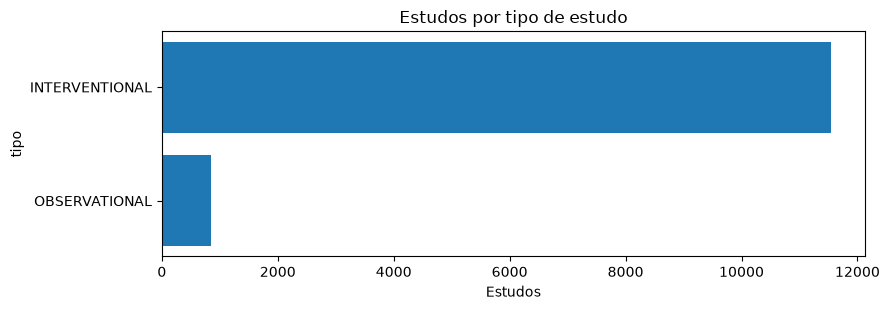

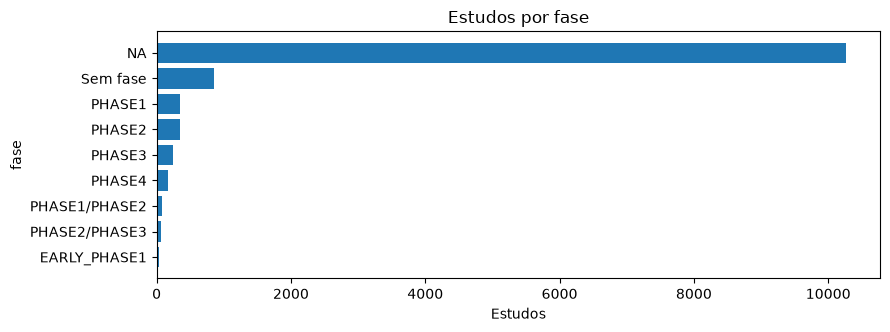

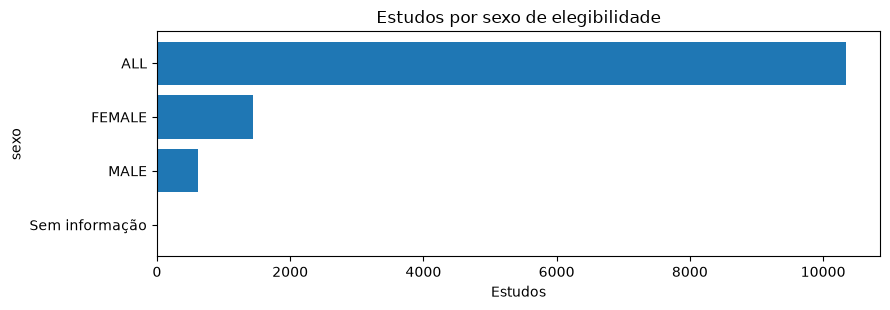

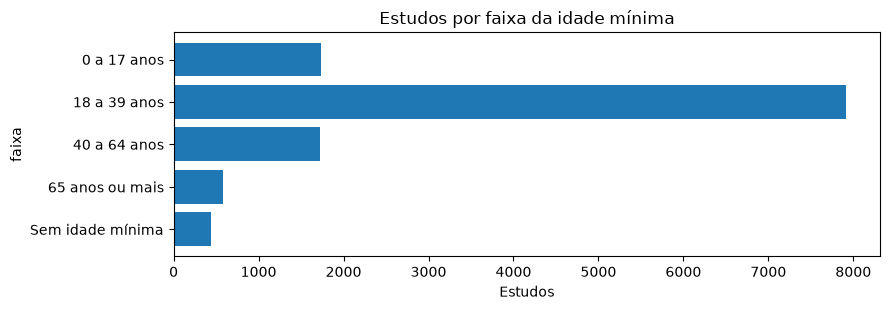

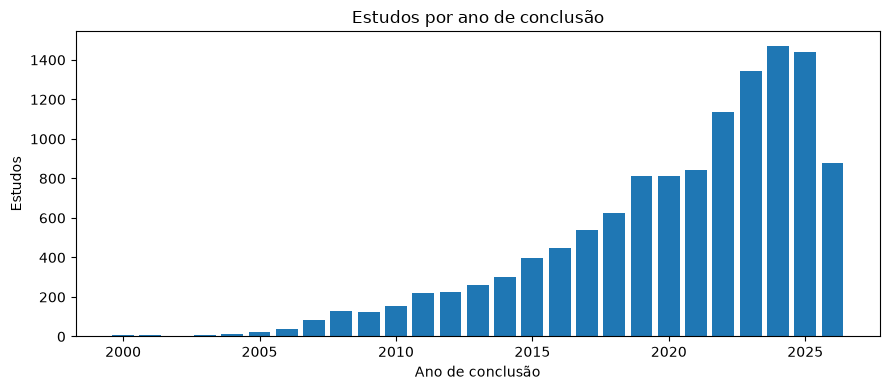

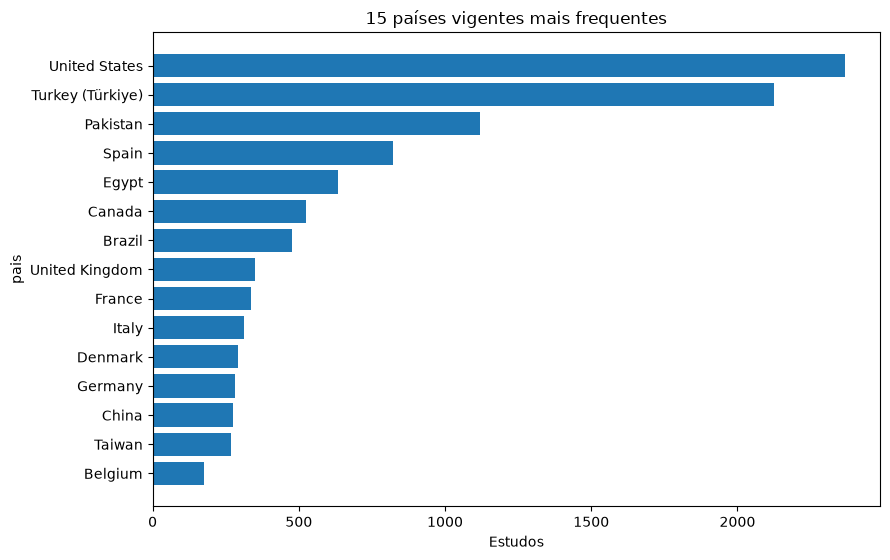

In [7]:
tipo_estudo = consultar(
    """
    SELECT coalesce(study_type, 'Sem informação') AS tipo, count(*) AS estudos
    FROM gold.estudos
    GROUP BY 1
    ORDER BY estudos DESC
    """
)
barras(tipo_estudo, "Estudos por tipo de estudo", "Estudos")

fase = consultar(
    """
    SELECT coalesce(phase, 'Sem fase') AS fase, count(*) AS estudos
    FROM gold.estudos
    GROUP BY 1
    ORDER BY estudos DESC
    """
)
barras(fase, "Estudos por fase", "Estudos")

sexo = consultar(
    """
    SELECT coalesce(gender, 'Sem informação') AS sexo, count(*) AS estudos
    FROM gold.estudos
    GROUP BY 1
    ORDER BY estudos DESC
    """
)
barras(sexo, "Estudos por sexo de elegibilidade", "Estudos")

idade = consultar(
    """
    SELECT
        CASE
            WHEN minimum_age_years IS NULL THEN 'Sem idade mínima'
            WHEN minimum_age_years < 18 THEN '0 a 17 anos'
            WHEN minimum_age_years < 40 THEN '18 a 39 anos'
            WHEN minimum_age_years < 65 THEN '40 a 64 anos'
            ELSE '65 anos ou mais'
        END AS faixa,
        count(*) AS estudos
    FROM gold.estudos
    GROUP BY 1
    """
)
ordem_idade = [
    "0 a 17 anos",
    "18 a 39 anos",
    "40 a 64 anos",
    "65 anos ou mais",
    "Sem idade mínima",
]
idade["faixa"] = pd.Categorical(idade["faixa"], ordem_idade, ordered=True)
idade = idade.sort_values("faixa")
barras(idade, "Estudos por faixa da idade mínima", "Estudos")

anos = consultar(
    """
    SELECT year(completion_date) AS ano, count(*) AS estudos
    FROM gold.estudos
    WHERE completion_date IS NOT NULL
      AND year(completion_date) BETWEEN 1990 AND 2026
    GROUP BY 1
    ORDER BY 1
    """
)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(anos["ano"], anos["estudos"])
ax.set_title("Estudos por ano de conclusão")
ax.set_xlabel("Ano de conclusão")
ax.set_ylabel("Estudos")
fig.tight_layout()
plt.show()

paises = consultar(
    """
    SELECT unnest.name AS pais, count(DISTINCT nct_id) AS estudos
    FROM gold.estudos, unnest(countries_current)
    WHERE unnest.name IS NOT NULL
    GROUP BY 1
    ORDER BY estudos DESC
    LIMIT 15
    """
)
barras(paises, "15 países vigentes mais frequentes", "Estudos")


## Evidência publicada

Resultado publicado é a flag do próprio registro. A busca PubMed conta citações: um estudo pode ter várias, e citação sem PMID não tem resumo baixado.


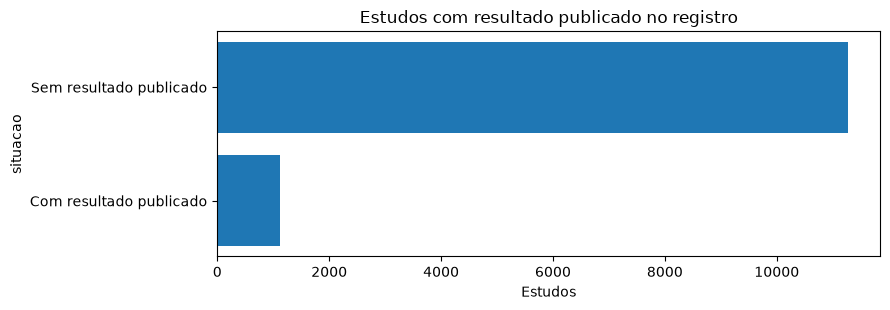

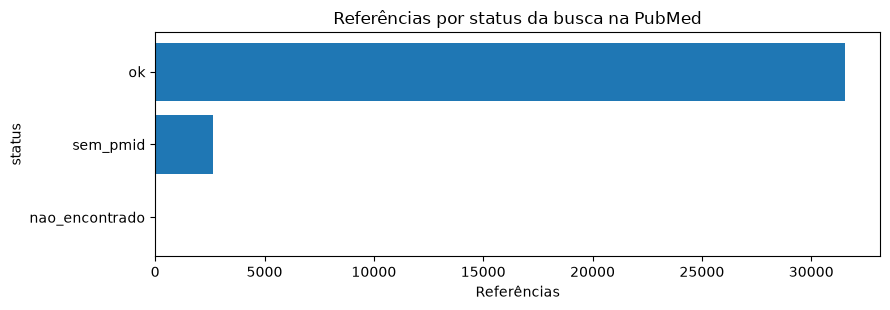

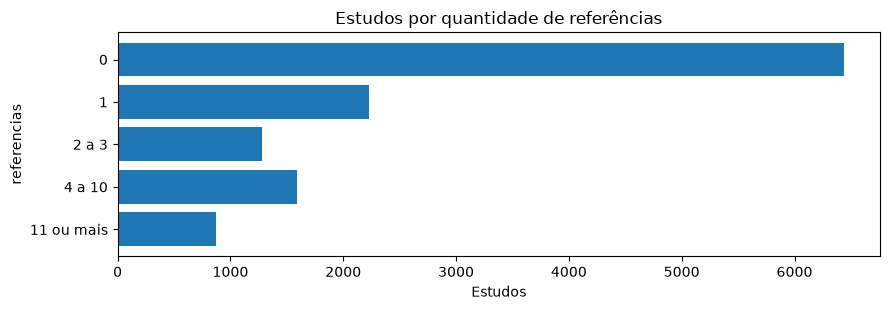

In [8]:
resultados = consultar(
    """
    SELECT
        CASE
            WHEN were_results_reported IS TRUE THEN 'Com resultado publicado'
            WHEN were_results_reported IS FALSE THEN 'Sem resultado publicado'
            ELSE 'Sem informação'
        END AS situacao,
        count(*) AS estudos
    FROM gold.estudos
    GROUP BY 1
    ORDER BY estudos DESC
    """
)
barras(resultados, "Estudos com resultado publicado no registro", "Estudos")

busca = consultar(
    """
    SELECT busca_status AS status, count(*) AS referencias
    FROM gold.referencias
    GROUP BY 1
    ORDER BY referencias DESC
    """
)
barras(busca, "Referências por status da busca na PubMed", "Referências")

faixas = consultar(
    """
    WITH por_estudo AS (
        SELECT g.nct_id, count(r.nct_id) AS referencias
        FROM gold.estudos AS g
        LEFT JOIN gold.referencias AS r ON r.nct_id = g.nct_id
        GROUP BY g.nct_id
    )
    SELECT
        CASE
            WHEN referencias = 0 THEN '0'
            WHEN referencias = 1 THEN '1'
            WHEN referencias BETWEEN 2 AND 3 THEN '2 a 3'
            WHEN referencias BETWEEN 4 AND 10 THEN '4 a 10'
            ELSE '11 ou mais'
        END AS referencias,
        count(*) AS estudos
    FROM por_estudo
    GROUP BY 1
    """
)
ordem_refs = ["0", "1", "2 a 3", "4 a 10", "11 ou mais"]
faixas["referencias"] = pd.Categorical(faixas["referencias"], ordem_refs, ordered=True)
faixas = faixas.sort_values("referencias")
barras(faixas, "Estudos por quantidade de referências", "Estudos")
